# 02 - Batting and bowling
Distributions and leaders. Career figures cover World Cups from 2003 only (ODI) and all T20 editions.

In [1]:
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
con = duckdb.connect(str(ROOT / "data" / "warehouse" / "cricket_gold.duckdb"), read_only=True)
q = lambda sql: con.execute(sql).fetchdf()
FMT = {"ODI": "#2a6fbb", "T20": "#e07b00"}   # one colour per format, used everywhere
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "figure.figsize": (9, 4.2)})
pd.set_option("display.width", 160)

## Innings totals

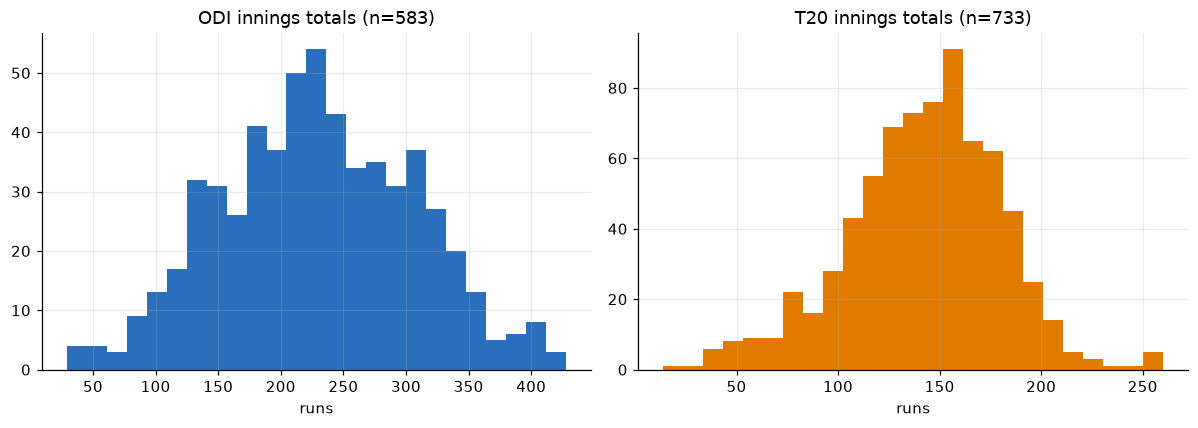

        count   mean   std   min    25%    50%    75%    max
format                                                      
ODI     583.0  229.3  77.6  29.0  177.0  227.0  286.0  428.0
T20     733.0  142.4  37.9  14.0  120.0  146.0  168.0  260.0


In [2]:
i = q("select format, total_runs, wickets, year from gold.fact_innings where not is_super_over and total_runs is not null")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, f in zip(axes, ["ODI", "T20"]):
    g = i[i.format == f]
    ax.hist(g.total_runs, bins=25, color=FMT[f]); ax.set_title(f"{f} innings totals (n={len(g)})"); ax.set_xlabel("runs")
plt.tight_layout(); plt.show()
print(i.groupby("format").total_runs.describe().round(1))

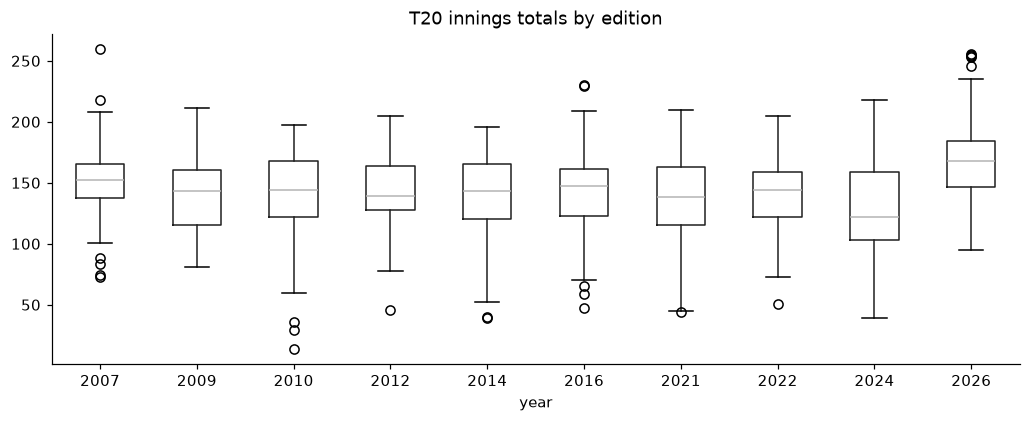

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
t = i[i.format == "T20"]
t.boxplot(column="total_runs", by="year", ax=ax, grid=False); ax.set_title("T20 innings totals by edition"); plt.suptitle("")
plt.show()

## Individual batting

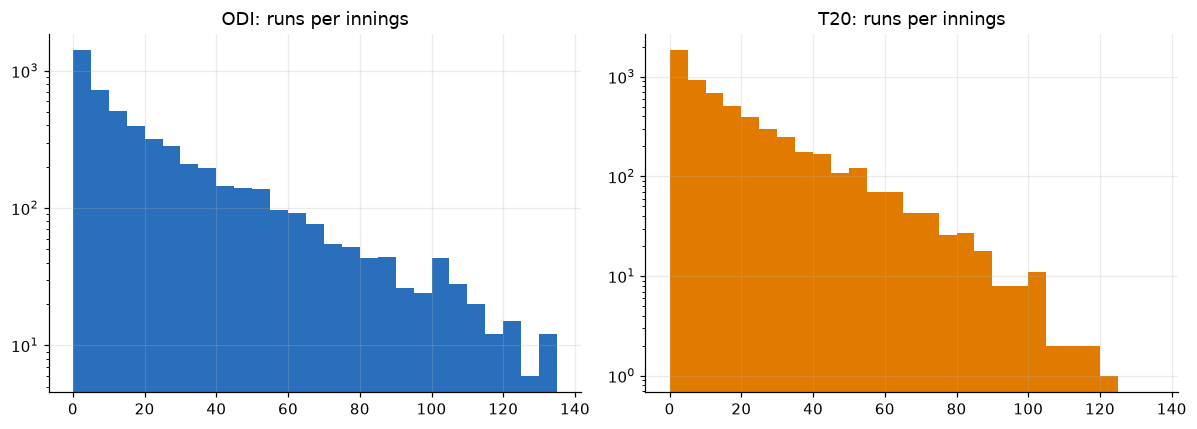

FINDING [ODI]: median 14 runs; 15.9% of innings reach 50; 10.4% are ducks
FINDING [T20]: median 11 runs; 7.8% of innings reach 50; 11.1% are ducks


In [4]:
p = q("""select f.runs, f.balls_faced, f.format, (not f.is_out) as not_out from gold.fact_player_performances f where f.did_bat and f.balls_faced > 0""")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, f in zip(axes, ["ODI", "T20"]):
    g = p[p.format == f]
    ax.hist(g.runs, bins=range(0, 140, 5), color=FMT[f]); ax.set_title(f"{f}: runs per innings"); ax.set_yscale("log")
plt.tight_layout(); plt.show()
for f, g in p.groupby("format"):
    print(f"FINDING [{f}]: median {g.runs.median():.0f} runs; {100*(g.runs>=50).mean():.1f}% of innings reach 50; {100*(g.runs==0).mean():.1f}% are ducks")

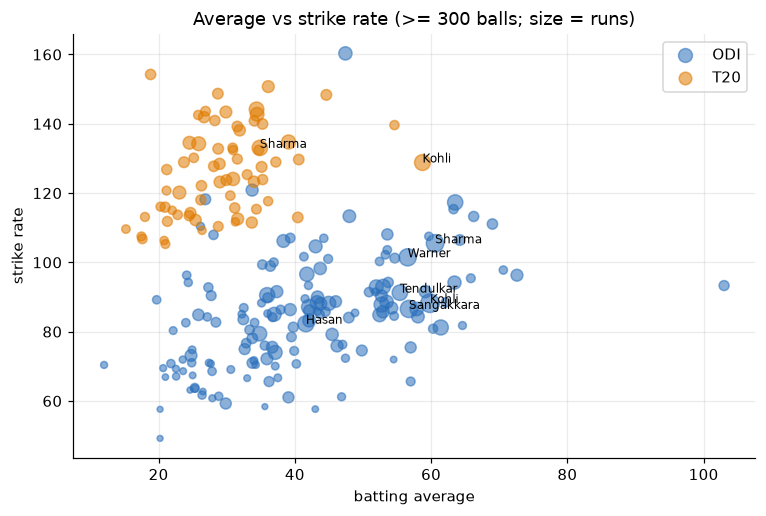

FINDING: correlation of average and strike rate: {'ODI': 0.44, 'T20': 0.38}


In [5]:
c = q("""select p.full_name, b.format, b.balls_faced, b.runs, b.strike_rate, b.average from gold.mart_batting_career b join gold.dim_players p using (player_id) where b.balls_faced >= 300""")
fig, ax = plt.subplots(figsize=(8, 5))
for f, g in c.groupby("format"):
    ax.scatter(g.average, g.strike_rate, s=g.runs / 12, alpha=.55, color=FMT[f], label=f)
for r in c.nlargest(8, "runs").itertuples():
    ax.annotate(r.full_name.split()[-1], (r.average, r.strike_rate), fontsize=8)
ax.set_xlabel("batting average"); ax.set_ylabel("strike rate"); ax.set_title("Average vs strike rate (>= 300 balls; size = runs)"); ax.legend()
plt.show()
print("FINDING: correlation of average and strike rate:", c.groupby("format").apply(lambda g: round(g.average.corr(g.strike_rate), 2), include_groups=False).to_dict())

## Bowling

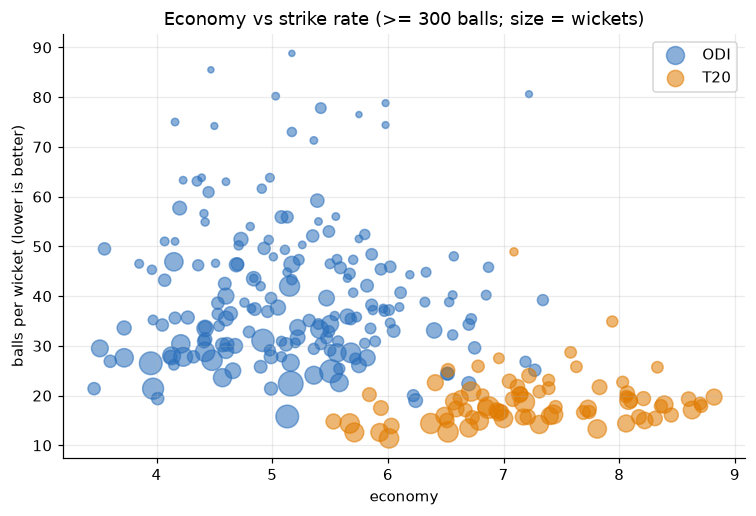

format              ODI   T20
dismissal_type               
caught             58.5  61.1
bowled             18.4  19.1
lbw                10.9   7.2
run out             6.7   6.8
caught and bowled   3.2   2.7
stumped             2.2   3.0
hit wicket          0.2   0.1
retired out         NaN   0.1


In [6]:
b = q("""select p.full_name, w.format, w.balls_bowled, w.wickets, w.economy, w.average, w.strike_rate from gold.mart_bowling_career w join gold.dim_players p using (player_id) where w.balls_bowled >= 300""")
fig, ax = plt.subplots(figsize=(8, 5))
for f, g in b.groupby("format"):
    ax.scatter(g.economy, g.strike_rate, s=g.wickets * 4, alpha=.55, color=FMT[f], label=f)
ax.set_xlabel("economy"); ax.set_ylabel("balls per wicket (lower is better)"); ax.set_title("Economy vs strike rate (>= 300 balls; size = wickets)"); ax.legend()
plt.show()
d = q("select m.format, d.dismissal_type, count(*) n from gold.fact_deliveries d join gold.fact_matches m using(match_id) where d.is_wicket and not d.is_super_over group by 1,2")
d["pct"] = 100 * d.n / d.groupby("format").n.transform("sum")
print(d.pivot(index="dismissal_type", columns="format", values="pct").round(1).sort_values("ODI", ascending=False))

In [7]:
w = q("select format, wickets, count(*) n from gold.fact_player_performances where did_bowl group by 1,2 order by 1,2")
print(w.pivot(index="wickets", columns="format", values="n").fillna(0).astype(int))
top = q("""select p.full_name, count(*) n from gold.fact_player_performances f join gold.dim_players p using(player_id) where f.wickets >= 4 group by 1 order by 2 desc limit 8""")
print("FINDING: bowlers with most 4+ wicket innings:", dict(zip(top.full_name, top.n)))

format    ODI   T20
wickets            
0        1355  1774
1        1015  1394
2         663   764
3         315   305
4         119    98
5          37    13
6           7     1
7           4     0


FINDING: bowlers with most 4+ wicket innings: {'Mohammed Shami': 8, 'Adam Zampa': 7, 'Shahid Afridi': 6, 'Imran Tahir': 6, 'Mitchell Starc': 6, 'Shakib Al Hasan': 5, 'Shaheen Shah Afridi': 5, 'Trent Boult': 5}
